# North Carolina Boating Access Atlas

This atlas maps public boating access areas across North Carolina counties. Using county boundaries from the U.S. Census Bureau and boating access locations from the NC Wildlife Resources Commission, a spatial join will calculate the number of boating access sites in each county.

Each page will display a county map, its boating access sites, a statewide locator map, and the results of the spatial join.

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages


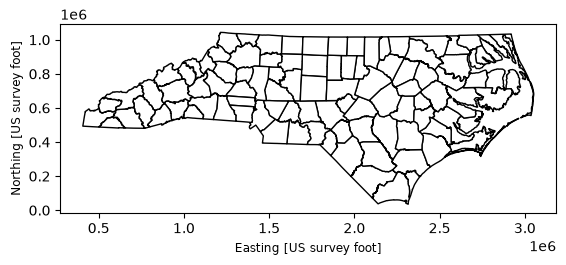

In [2]:
url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/"
url_county = "cb_2024_us_county_500k.zip"

counties = gpd.read_file(url_0 + url_county)

nc_counties = counties.loc[counties["STATEFP"] == "37"].to_crs(6543).copy()

nc_counties.plot(edgecolor="black", facecolor="white")
plt.show()

In [3]:
# NC Wildlife Resources Commission boating access locations
url = ("https://services1.arcgis.com/YfqBAUM5nWR3yhGP/"
    "arcgis/rest/services/"
    "NCWRC_Boating_Access_Areas_view/FeatureServer/0/query"
    "?where=1%3D1&outFields=*&returnGeometry=true"
    "&outSR=4326&f=geojson")

boat_ramps = gpd.read_file(url)

boat_ramps = boat_ramps.to_crs(nc_counties.crs)

print("Boating access sites loaded:", len(boat_ramps))
print("Geometry types:", boat_ramps.geom_type.unique())

boat_ramps.head()

Boating access sites loaded: 267
Geometry types: <StringArray>
['Point']
Length: 1, dtype: str


,OBJECTID,Site_Status,BAA_Name,BAA_Alias,Water_Access,Region,Work_Area,Maintenance,Street,City,...,Non_Motorized_Access,Caution_Notes,Kiosk,Restroom,Trash_Can,Lighting,Closure_Reason,GlobalID,Portable_Boat_Access_Type,geometry
0,1,OPEN,BOWSERTOWN ROAD,CROATAN SOUND,CROATAN SOUND,COASTAL,NORTHERN COAST,WRC COLUMBIA DEPOT,168 S CALIFORNIA LN,MANTEO,...,0,NaN,1.0,1.0,0.0,0.0,NaN,9bc4aef9-e685-478d-92f5-7cb70e51c5b0,NaN,POINT (2983956.228 798293.482)
1,2,OPEN,AVALON BEACH,NaN,KITTY HAWK BAY,COASTAL,NORTHERN COAST,WRC COLUMBIA DEPOT,2028 BAY DR,KILL DEVIL HILLS,...,1,NaN,1.0,0.0,0.0,0.0,NaN,12d1e049-373c-403f-b1a6-0c6dbbfda07a,NaN,POINT (2979499.096 848210.228)
2,3,OPEN,WASHINGTON BAUM BRIDGE,"MANTEO, PIRATES COVE",ROANOKE SOUND,COASTAL,NORTHERN COAST,WRC COLUMBIA DEPOT,1205 NORTH HWY,MANTEO,...,1,NaN,1.0,1.0,1.0,1.0,NaN,b34f02a6-8c55-4b00-960a-b92766d41bc6,NaN,POINT (2995705.804 797125.318)
3,4,OPEN,MASHOES,NaN,EAST LAKE,COASTAL,NORTHERN COAST,WRC COLUMBIA DEPOT,2081 MASHOES RD,MANNS HARBOR,...,0,NaN,1.0,0.0,0.0,0.0,NaN,76f64a1c-2a6f-4716-846b-108813986a50,NaN,POINT (2942881.82 807903.541)
4,6,OPEN,STUMPY POINT,NaN,PAMLICO SOUND,COASTAL,NORTHERN COAST,WRC COLUMBIA DEPOT,321 BAYVIEW DR,STUMPY POINT,...,0,NaN,1.0,0.0,0.0,1.0,NaN,bf2c59dc-8a1b-4ec5-9714-b885647747bb,NaN,POINT (2968745.288 721763.112)


In [5]:
ramps_by_county = gpd.sjoin(boat_ramps, nc_counties[["NAME", "geometry"]], how="inner", predicate="within")

ramp_counts = ramps_by_county.groupby("NAME").size()

nc_counties["ramp_count"] = (nc_counties["NAME"].map(ramp_counts).fillna(0).astype(int))

nc_counties[["NAME", "ramp_count"]].head(10)

,NAME,ramp_count
90,Columbus,2
91,Cherokee,4
92,Polk,1
93,Ashe,1
94,Dare,7
95,Hertford,3
217,Wilkes,1
218,Rowan,3
219,Henderson,2
220,Sampson,1


## Creating County Atlas Maps

The following functions create individual county maps and statewide locator maps. Each county map displays public boating access locations identified through the spatial join.

In [7]:
def county_map(county, ax):
    selected = nc_counties[nc_counties["NAME"] == county]

    selected.plot(ax=ax, edgecolor="black", facecolor="#b7d6cc")

    county_ramps = ramps_by_county[ramps_by_county["NAME"] == county]

    if not county_ramps.empty:
        county_ramps.plot(
            ax=ax,
            color="#176b98",
            markersize=45,
            edgecolor="white")

    ax.set_axis_off()


def locator_map(county, ax):
    selected = nc_counties[nc_counties["NAME"] == county]

    nc_counties.plot(
        ax=ax,
        edgecolor="gray",
        facecolor="white",
        linewidth=0.4)

    selected.plot(
        ax=ax,
        edgecolor="black",
        facecolor="#176b98")

    ax.set_axis_off()

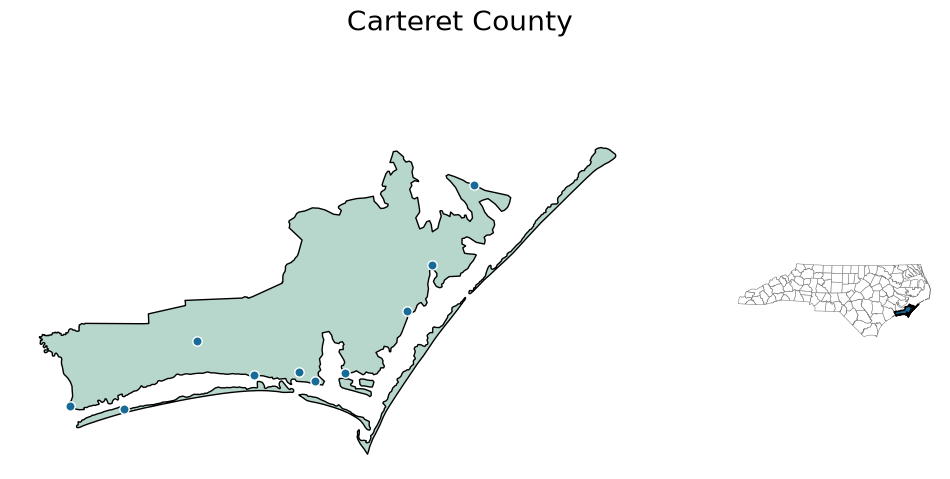

In [8]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 6),
    gridspec_kw={"width_ratios": [3, 1]})

county_map("Carteret", axes[0])
locator_map("Carteret", axes[1])

fig.suptitle("Carteret County", fontsize=20)
plt.show()

In [9]:
def county_info(county, ax):
    selected = nc_counties[nc_counties["NAME"] == county]

    count = int(selected["ramp_count"].iloc[0])

    message = (
        "There are " + str(count) +
        " public boating access sites in " +
        county + " County.")

    ax.text(
        0.05, 0.6,
        message,
        transform=ax.transAxes,
        fontsize=13,
        wrap=True)

    ax.set_axis_off()


In [10]:
def county_figure(county, pdf):
    fig = plt.figure(figsize=(12, 8))

    ax_county = fig.add_axes([0.05, 0.20, 0.55, 0.60])
    ax_locator = fig.add_axes([0.67, 0.48, 0.28, 0.28])
    ax_info = fig.add_axes([0.65, 0.18, 0.32, 0.23])

    county_map(county, ax_county)
    locator_map(county, ax_locator)
    county_info(county, ax_info)

    fig.text(
        0.05, 0.94,
        "NORTH CAROLINA / PUBLIC BOATING ACCESS ATLAS",
        fontsize=10,
        color="#176b98")

    fig.text(
        0.05, 0.86,
        county + " County",
        fontsize=28,
        fontweight="bold")

    fig.text(
        0.05, 0.03,
        "Sources: U.S. Census Bureau | NC Wildlife Resources Commission",
        fontsize=9,
        color="gray")

    pdf.savefig(fig, dpi=150)
    plt.close(fig)

In [11]:
test_counties = ["Carteret", "Onslow", "New Hanover"]

with PdfPages("NC_Boating_Atlas_Test.pdf") as pdf:
    for county in test_counties:
        county_figure(county, pdf)

print("Test atlas created successfully!")

Test atlas created successfully!


In [12]:
nc_counties = nc_counties.sort_values("NAME").reset_index(drop=True)

with PdfPages("NC_Boating_Atlas.pdf") as pdf:
    for county in nc_counties["NAME"]:
        county_figure(county, pdf)

print("Complete atlas created!")


Complete atlas created!


In [13]:
# Export two example atlas pages
with PdfPages("NC_Boating_Atlas_Samples.pdf") as pdf:
    for county in ["Carteret", "Wake"]:
        county_figure(county, pdf)

print("Sample pages ready for submission!")

Sample pages ready for submission!
